In [9]:
import json, random, shutil
from pathlib import Path

SRC = Path("/kaggle/input/datasets/emmarex/plantdisease/PlantVillage")
DST = Path("/kaggle/working/data")
SEED = 42
CAP = 1500

CLASS_MAP = {
    "Potato___Early_blight": "Potato___Early_blight",
    "Potato___Late_blight": "Potato___Late_blight",
    "Potato___healthy": "Potato___healthy",
    "Tomato_Bacterial_spot": "Tomato___Bacterial_spot",
    "Tomato_Early_blight": "Tomato___Early_blight",
    "Tomato_Late_blight": "Tomato___Late_blight",
    "Tomato_Leaf_Mold": "Tomato___Leaf_Mold",
    "Tomato_Septoria_leaf_spot": "Tomato___Septoria_leaf_spot",
    "Tomato_Spider_mites_Two_spotted_spider_mite": "Tomato___Spider_mites",
    "Tomato__Target_Spot": "Tomato___Target_Spot",
    "Tomato__Tomato_YellowLeaf__Curl_Virus": "Tomato___Yellow_Leaf_Curl_Virus",
    "Tomato__Tomato_mosaic_virus": "Tomato___Mosaic_virus",
    "Tomato_healthy": "Tomato___healthy",
}

if DST.exists():
    shutil.rmtree(DST)

classes = sorted(CLASS_MAP.values())
rng = random.Random(SEED)
print(f"{'class':45s} train  val  test")

for src_name, clean in sorted(CLASS_MAP.items(), key=lambda x: x[1]):
    files = sorted(p for p in (SRC / src_name).iterdir()
                   if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
    rng.shuffle(files)
    files = files[:CAP]
    n = len(files)
    n_train, n_val = int(n * 0.70), int(n * 0.15)
    splits = {
        "train": files[:n_train],
        "val": files[n_train:n_train + n_val],
        "test": files[n_train + n_val:],
    }
    for split, items in splits.items():
        out = DST / split / clean
        out.mkdir(parents=True, exist_ok=True)
        for p in items:
            shutil.copy(p, out / p.name)
    print(f"{clean:45s} {len(splits['train']):5d} {len(splits['val']):4d} {len(splits['test']):5d}")

with open("/kaggle/working/classes.json", "w") as f:
    json.dump(classes, f, indent=2)
print("\nSaved classes.json with", len(classes), "classes")

class                                         train  val  test
Potato___Early_blight                           700  150   150
Potato___Late_blight                            700  150   150
Potato___healthy                                106   22    24
Tomato___Bacterial_spot                        1050  225   225
Tomato___Early_blight                           700  150   150
Tomato___Late_blight                           1050  225   225
Tomato___Leaf_Mold                              666  142   144
Tomato___Mosaic_virus                           261   55    57
Tomato___Septoria_leaf_spot                    1050  225   225
Tomato___Spider_mites                          1050  225   225
Tomato___Target_Spot                            982  210   212
Tomato___Yellow_Leaf_Curl_Virus                1050  225   225
Tomato___healthy                               1050  225   225

Saved classes.json with 13 classes


In [10]:
import os
print(len(os.listdir("/kaggle/working/data/train")), "classes in train")

13 classes in train


In [11]:
import time, torch, torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)
torch.manual_seed(42)

DATA = "/kaggle/working/data"
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.3, 0.3, 0.3, 0.05),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder(f"{DATA}/train", transform=train_tf)
val_ds = datasets.ImageFolder(f"{DATA}/val", transform=eval_tf)
print("Classes:", len(train_ds.classes))

# Class order must match classes.json
import json
saved = json.load(open("/kaggle/working/classes.json"))
assert saved == train_ds.classes, "Class order mismatch!"

train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
val_dl = DataLoader(val_ds, batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

# Class weights (softened) so small classes are not ignored
counts = torch.bincount(torch.tensor(train_ds.targets))
weights = (counts.sum() / (len(counts) * counts.float())) ** 0.5
criterion = nn.CrossEntropyLoss(weight=weights.to(device))

# Model: MobileNetV3-Small with ImageNet weights, new 13-class output layer
model = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1)
model.classifier[3] = nn.Linear(model.classifier[3].in_features, len(train_ds.classes))
model = model.to(device)

def run_epoch(loader, train, optimizer=None):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)
            if train:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

best_val = 0.0

def train_stage(name, epochs, lr, freeze_backbone):
    global best_val
    for p in model.features.parameters():
        p.requires_grad = not freeze_backbone
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(train_dl, True, optimizer)
        va_loss, va_acc = run_epoch(val_dl, False)
        scheduler.step()
        flag = ""
        if va_acc > best_val:
            best_val = va_acc
            torch.save(model.state_dict(), "/kaggle/working/best_model.pth")
            flag = "  <- saved"
        print(f"[{name}] epoch {epoch}/{epochs}  train acc {tr_acc:.3f}  "
              f"val acc {va_acc:.3f}  val loss {va_loss:.3f}  ({time.time()-t0:.0f}s){flag}")

train_stage("head only", epochs=4, lr=1e-3, freeze_backbone=True)
train_stage("fine-tune", epochs=12, lr=3e-4, freeze_backbone=False)
print("Best validation accuracy:", round(best_val, 4))

Using: cuda
Classes: 13
[head only] epoch 1/4  train acc 0.723  val acc 0.729  val loss 0.787  (49s)  <- saved
[head only] epoch 2/4  train acc 0.822  val acc 0.842  val loss 0.452  (49s)  <- saved
[head only] epoch 3/4  train acc 0.847  val acc 0.862  val loss 0.387  (49s)  <- saved
[head only] epoch 4/4  train acc 0.872  val acc 0.900  val loss 0.306  (48s)  <- saved
[fine-tune] epoch 1/12  train acc 0.923  val acc 0.917  val loss 0.220  (50s)  <- saved
[fine-tune] epoch 2/12  train acc 0.958  val acc 0.946  val loss 0.153  (50s)  <- saved
[fine-tune] epoch 3/12  train acc 0.967  val acc 0.954  val loss 0.140  (50s)  <- saved
[fine-tune] epoch 4/12  train acc 0.979  val acc 0.970  val loss 0.085  (49s)  <- saved
[fine-tune] epoch 5/12  train acc 0.982  val acc 0.983  val loss 0.051  (49s)  <- saved
[fine-tune] epoch 6/12  train acc 0.986  val acc 0.986  val loss 0.043  (49s)  <- saved
[fine-tune] epoch 7/12  train acc 0.988  val acc 0.988  val loss 0.035  (49s)  <- saved
[fine-tune] 

Test accuracy: 0.9902
                                 precision    recall  f1-score   support

          Potato___Early_blight      1.000     1.000     1.000       150
           Potato___Late_blight      1.000     0.980     0.990       150
               Potato___healthy      0.960     1.000     0.980        24
        Tomato___Bacterial_spot      0.991     0.991     0.991       225
          Tomato___Early_blight      0.980     0.987     0.983       150
           Tomato___Late_blight      0.986     0.969     0.978       225
             Tomato___Leaf_Mold      0.993     1.000     0.997       144
          Tomato___Mosaic_virus      0.983     1.000     0.991        57
    Tomato___Septoria_leaf_spot      0.987     1.000     0.993       225
          Tomato___Spider_mites      0.978     0.982     0.980       225
           Tomato___Target_Spot      0.991     0.991     0.991       212
Tomato___Yellow_Leaf_Curl_Virus      0.996     0.991     0.993       225
               Tomato___heal

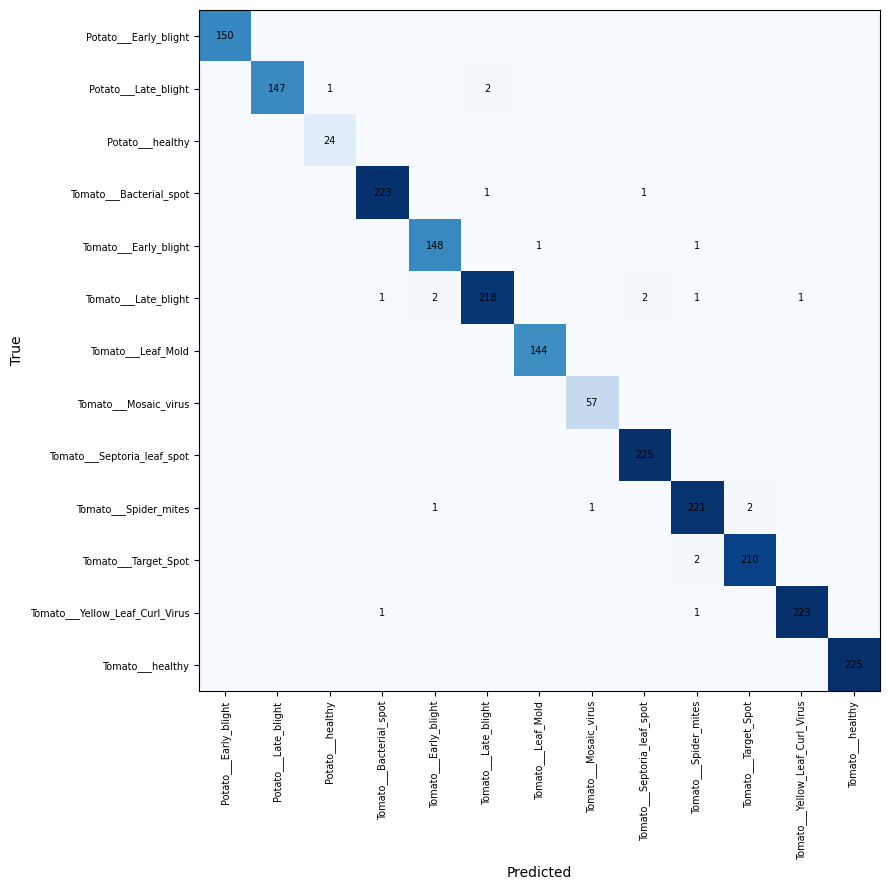

In [12]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report

test_ds = datasets.ImageFolder(f"{DATA}/test", transform=eval_tf)
assert test_ds.classes == saved
test_dl = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=2)

model.load_state_dict(torch.load("/kaggle/working/best_model.pth", map_location=device))
model.eval()

preds, labels = [], []
with torch.no_grad():
    for x, y in test_dl:
        preds += model(x.to(device)).argmax(1).cpu().tolist()
        labels += y.tolist()

preds, labels = np.array(preds), np.array(labels)
print("Test accuracy:", round((preds == labels).mean(), 4))
print(classification_report(labels, preds, target_names=test_ds.classes, digits=3))

cm = confusion_matrix(labels, preds)
fig, ax = plt.subplots(figsize=(10, 9))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(test_ds.classes))); ax.set_yticks(range(len(test_ds.classes)))
ax.set_xticklabels(test_ds.classes, rotation=90, fontsize=7)
ax.set_yticklabels(test_ds.classes, fontsize=7)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=7)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout()
plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150)
plt.show()